# Optimización de Tiempos de Atención en Urgencias mediante Modelos Predictivos de Machine Learning

### ¡SIGU - Sistema Inteligente de Gestion de Urgencias!

Se descargó el dataset en un csv para poder hacer el experimento reproducible del sitio oficial de datos abiertos

Informacion del Dataset: Clasificación en Triage Urgencias Salud y Protección Social\
Registros de usuarios que fueron atendidos y clasificados en triage en los servicios de urgencias de las Instituciones prestadoras de servicios de salud de la Empresa Social del Estado Pasto Salud. Es un indicador de Calidad de la resolución 256

Enlace: https://www.datos.gov.co/Salud-y-Protecci-n-Social/Clasificaci-n-en-Triage-Urgencias/vt5n-eu2r/about_data

**Objetivo del notebook:** 
limpiar el dataset de triage y generar los archivos listos para usar en 'backend.py' y 'app.py':\
'urgencias_limpio.csv' → un registro por atención (espera, llegadas, día, hora…)\
'llegadas_ips_hora.csv' → ingresos por IPS y hora (incluye horas con 0), para Poisson

In [2]:
# Importamos las librerias necesarias

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

In [ ]:
# Definimos constantes

RUTA_CRUDO = Path(r"C:\Users\soporte.sistemas\RepoLocal\Unicafam\Project_Analitica_II\data\Clasificación_en_Triage_Urgencias_20261003.csv")
CARPETA_SALIDA = Path(r"C:\Users\soporte.sistemas\RepoLocal\Unicafam\Project_Analitica_II\data")
ANIO = 2022                 # Año de análisis (igual al informe)
FORMATO_FECHA = "%Y %b %d %I:%M:%S %p"
MAX_ESPERA_MIN = None       # Ej. 360 si decides recortar registros extremos; None = no recortar
MAX_SALTO_LLEGADAS = 1440   # Saltos > 24 h entre llegadas se consideran huecos de registro

MAPA_DIAS = {
    "Monday": "Lunes", "Tuesday": "Martes", "Wednesday": "Miércoles",
    "Thursday": "Jueves", "Friday": "Viernes", "Saturday": "Sábado", "Sunday": "Domingo",
}
DIAS_ORDEN = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
TRIAGE_ORDEN = ["I", "II", "III", "IV", "V"]

In [4]:
# Cargamos los datos originales tal como vienen de la fuente.

def cargar_crudo(ruta: Path = RUTA_CRUDO) -> pd.DataFrame:
    return pd.read_csv(ruta, encoding="latin-1")

data = cargar_crudo()
calidad = [("Registros iniciales", len(data))]   # Control de limpieza para el informe
print(data.shape)
data.info()

(89453, 9)
<class 'pandas.DataFrame'>
RangeIndex: 89453 entries, 0 to 89452
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CodAdminis      89452 non-null  str  
 1   Nom_Admini      89452 non-null  str  
 2   Fecha_Ing       89453 non-null  str  
 3   Hora_Ingre      89453 non-null  str  
 4   Fecha_Atencion  89453 non-null  str  
 5   Hora_Atencion   89453 non-null  str  
 6   Triage          89453 non-null  str  
 7   Ips             89453 non-null  str  
 8   Red             89453 non-null  str  
dtypes: str(9)
memory usage: 6.1 MB


In [5]:
# Calculamos variable de frannja horaria

def asignar_franja(hora: int) -> str:
    if 6 <= hora < 12:
        return "Mañana (06:00 - 11:59)"
    elif 12 <= hora < 18:
        return "Tarde (12:00 - 17:59)"
    elif 18 <= hora < 24:
        return "Noche (18:00 - 23:59)"
    return "Madrugada (00:00 - 05:59)"

In [6]:
# Devuelve el DataFrame limpio (paso, registros restantes).

def limpiar(data: pd.DataFrame, anio: int = ANIO) -> tuple[pd.DataFrame, list]:
    log = [("Registros iniciales", len(data))]
    df = data.copy()

    # Nombres de columnas sin espacios
    df.columns = df.columns.str.strip()

    # Duplicados
    df = df.drop_duplicates()
    log.append(("Sin duplicados", len(df)))

    # Fechas completas (Hora_Ingre / Hora_Atencion traen año 1900, se ignoran)
    df["dt_ingreso"] = pd.to_datetime(df["Fecha_Ing"], format=FORMATO_FECHA, errors="coerce")
    df["dt_atencion"] = pd.to_datetime(df["Fecha_Atencion"], format=FORMATO_FECHA, errors="coerce")
    df = df.dropna(subset=["dt_ingreso", "dt_atencion"])
    log.append(("Con fechas válidas", len(df)))

    # Solo el año de análisis
    df = df[df["dt_ingreso"].dt.year == anio]
    log.append((f"Solo año {anio}", len(df)))

    # Variable principal: tiempo de espera (min) y eliminación de negativos
    df["tiempo_espera_min"] = (df["dt_atencion"] - df["dt_ingreso"]).dt.total_seconds() / 60.0
    df = df[df["tiempo_espera_min"] >= 0]
    log.append(("Sin esperas negativas", len(df)))

    if MAX_ESPERA_MIN is not None:
        df = df[df["tiempo_espera_min"] <= MAX_ESPERA_MIN]
        log.append((f"Espera <= {MAX_ESPERA_MIN} min", len(df)))

    # Categóricas
    df["Triage"] = df["Triage"].astype(str).str.strip().str.upper()
    df["Nom_Admini"] = df["Nom_Admini"].fillna("NO REPORTADA")

    # Variables de tiempo (días en español sin depender del idioma del sistema)
    df["hora_dia"] = df["dt_ingreso"].dt.hour
    df["dia_semana"] = df["dt_ingreso"].dt.day_name().map(MAPA_DIAS)
    df["anio_mes"] = df["dt_ingreso"].dt.to_period("M").astype(str)
    df["franja_horaria"] = df["hora_dia"].apply(asignar_franja)

    # Tiempo entre llegadas por IPS (sin rellenar: los NaN se quedan como NaN)
    df = df.sort_values(["Ips", "dt_ingreso"]).reset_index(drop=True)
    tel = df.groupby("Ips")["dt_ingreso"].diff().dt.total_seconds() / 60.0
    df["tiempo_entre_llegadas_min"] = tel.where(tel <= MAX_SALTO_LLEGADAS)

    # Redondeo y columnas finales
    df["tiempo_espera_min"] = df["tiempo_espera_min"].round(2)
    df["tiempo_entre_llegadas_min"] = df["tiempo_entre_llegadas_min"].round(2)
    columnas_finales = [
        "dt_ingreso", "dt_atencion", "anio_mes", "dia_semana", "hora_dia",
        "franja_horaria", "Triage", "Ips", "Red", "Nom_Admini",
        "tiempo_espera_min", "tiempo_entre_llegadas_min",
    ]
    return df[columnas_finales].copy(), log


data_limpio, calidad = limpiar(data)
tabla_calidad = pd.DataFrame(calidad, columns=["Paso", "Registros"])
tabla_calidad["Eliminados"] = (-tabla_calidad["Registros"].diff()).fillna(0).astype(int)
tabla_calidad   # ← Tabla para la sección de calidad de datos del informe

,Paso,Registros,Eliminados
0,Registros iniciales,89453,0
1,Sin duplicados,79521,9932
2,Con fechas válidas,79521,0
3,Solo año 2022,42162,37359
4,Sin esperas negativas,42146,16


In [7]:
# Tabla de llegadas por IPS y hora (para Poisson)
# Cuenta ingresos por IPS en cada hora, incluyendo las horas 
# con 0 llegadas entre el primer y el último registro de cada IPS.

def llegadas_por_ips_hora(df: pd.DataFrame) -> pd.DataFrame:
    
    tmp = df.assign(hora=df["dt_ingreso"].dt.floor("h"))
    partes = []
    for ips, g in tmp.groupby("Ips"):
        conteo = g.groupby("hora").size()
        rango = pd.date_range(conteo.index.min(), conteo.index.max(), freq="h")
        conteo = conteo.reindex(rango, fill_value=0)
        partes.append(pd.DataFrame({"Ips": ips, "hora": rango, "llegadas": conteo.values}))
    return pd.concat(partes, ignore_index=True)


llegadas = llegadas_por_ips_hora(data_limpio)
print(f"Bloques IPS-hora: {len(llegadas):,}")
print(f"λ (media de llegadas por hora): {llegadas['llegadas'].mean():.3f}")
print(f"Varianza: {llegadas['llegadas'].var():.3f}  (en una Poisson ≈ λ)")

Bloques IPS-hora: 23,841
λ (media de llegadas por hora): 1.768
Varianza: 5.161  (en una Poisson ≈ λ)


In [8]:
# Verificación rápida Descriptiva de la espera por triage.

def resumen(df: pd.DataFrame) -> pd.DataFrame:
    return (df.groupby("Triage")["tiempo_espera_min"]
              .agg(n="count", media="mean", mediana="median", de="std",
                   minimo="min", q1=lambda s: s.quantile(.25),
                   q3=lambda s: s.quantile(.75), maximo="max")
              .reindex([t for t in TRIAGE_ORDEN if t in df["Triage"].unique()])
              .round(2))


print(f"Registros limpios: {len(data_limpio):,}")
print(f"Espera promedio:  {data_limpio['tiempo_espera_min'].mean():.2f} min")
print(f"Espera mediana:   {data_limpio['tiempo_espera_min'].median():.2f} min")
print("Nulos por columna:\n", data_limpio.isna().sum())
resumen(data_limpio)

Registros limpios: 42,146
Espera promedio:  63.07 min
Espera mediana:   46.00 min
Nulos por columna:
 dt_ingreso                    0
dt_atencion                   0
anio_mes                      0
dia_semana                    0
hora_dia                      0
franja_horaria                0
Triage                        0
Ips                           0
Red                           0
Nom_Admini                    0
tiempo_espera_min             0
tiempo_entre_llegadas_min    40
dtype: int64


,n,media,mediana,de,minimo,q1,q3,maximo
Triage,,,,,,,,
I,72,33.75,17.95,36.23,2.00,10.15,48.01,159.0
II,1254,38.27,28.00,33.79,1.00,14.12,49.71,187.0
III,36273,58.17,42.00,49.03,0.00,19.00,86.00,199.0
IV,4279,108.44,94.00,69.89,1.33,56.00,146.00,360.0
V,268,126.03,106.50,77.49,3.68,70.75,162.06,356.0


In [9]:
# Gráficos de control

def grafico_mediana_triage(df: pd.DataFrame, triages=("I", "II", "III")):
    colores = {"I": "#d9534f", "II": "#f0ad4e", "III": "#1f77b4", "IV": "#5cb85c", "V": "#999999"}
    sub = df[df["Triage"].isin(triages)]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.barplot(data=sub, x="Triage", y="tiempo_espera_min", order=list(triages),
                estimator="median", errorbar=None, hue="Triage", legend=False,
                palette=colores, ax=ax)
    ax.set_title(f"Mediana de espera por triage ({', '.join(triages)})")
    ax.set_ylabel("Minutos")
    fig.tight_layout()
    return fig

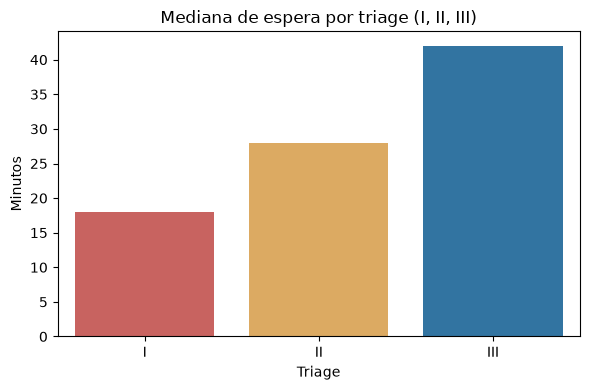

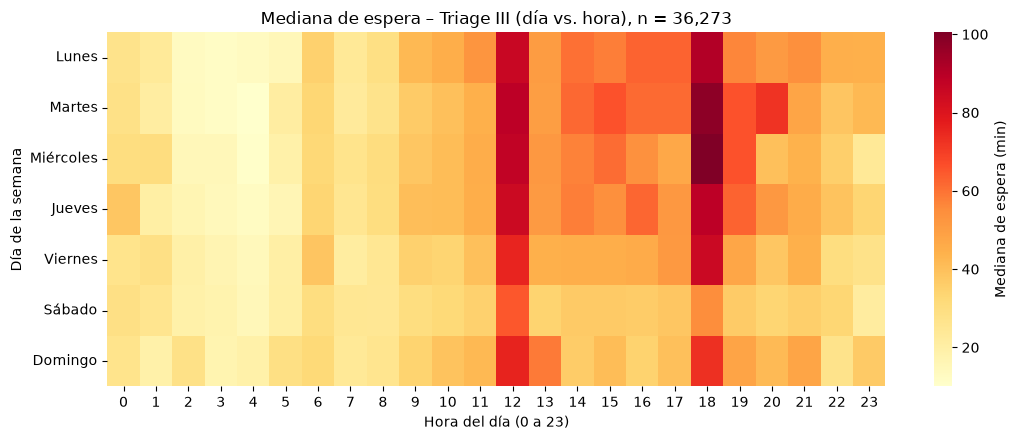

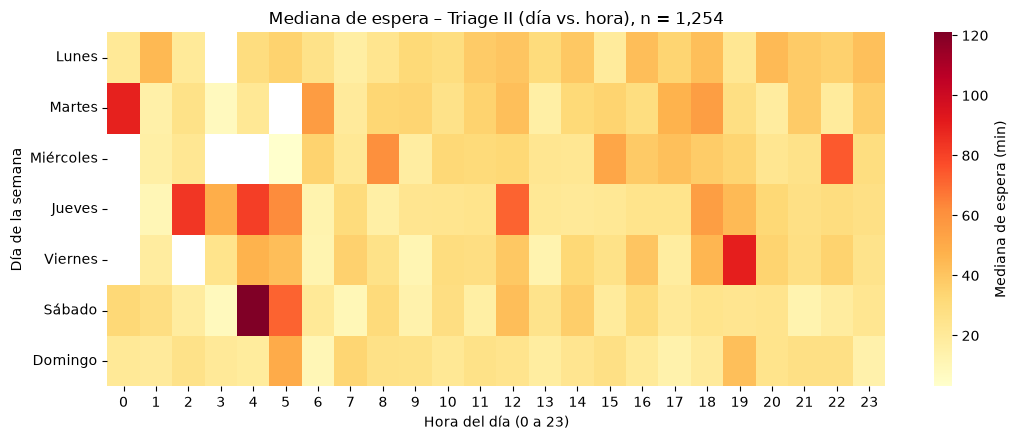

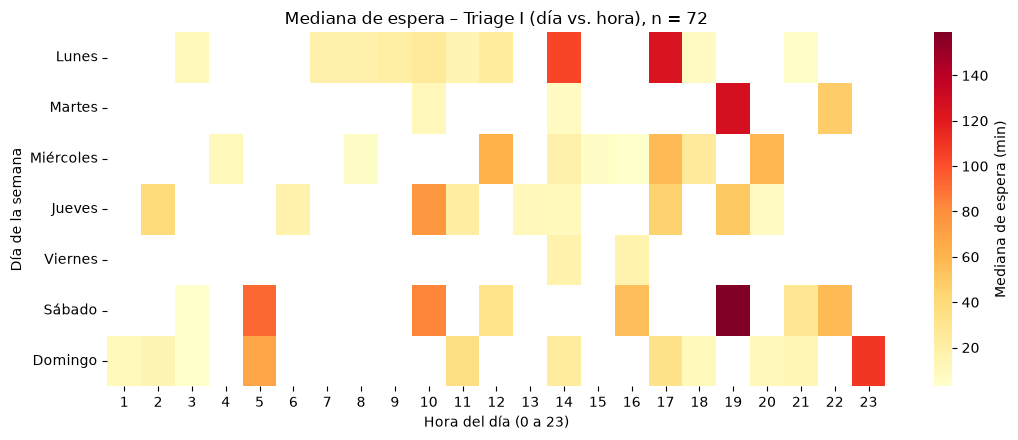

In [10]:
# Gráficos de control, Mediana de espera día × hora para un triage 

def mapa_calor_triage(df: pd.DataFrame, triage: str):
    sub = df[df["Triage"] == triage]
    tabla = (sub.pivot_table(index="dia_semana", columns="hora_dia",
                             values="tiempo_espera_min", aggfunc="median")
                .reindex(DIAS_ORDEN))
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.heatmap(tabla, cmap="YlOrRd", cbar_kws={"label": "Mediana de espera (min)"}, ax=ax)
    ax.set_title(f"Mediana de espera – Triage {triage} (día vs. hora), n = {len(sub):,}")
    ax.set_xlabel("Hora del día (0 a 23)")
    ax.set_ylabel("Día de la semana")
    fig.tight_layout()
    return fig


grafico_mediana_triage(data_limpio)
plt.show()
for t in ["III", "II", "I"]:
    mapa_calor_triage(data_limpio, t)   # Triage I tiene pocos datos: el mapa saldrá con huecos
    plt.show()

In [11]:
# Exportamos para backend.py / app.py

CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
data_limpio.to_csv(CARPETA_SALIDA / "urgencias_limpio.csv", index=False, encoding="utf-8-sig")
llegadas.to_csv(CARPETA_SALIDA / "llegadas_ips_hora.csv", index=False, encoding="utf-8-sig")
tabla_calidad.to_csv(CARPETA_SALIDA / "tabla_calidad.csv", index=False, encoding="utf-8-sig")
print("Archivos guardados en", CARPETA_SALIDA.resolve())

Archivos guardados en C:\Users\soporte.sistemas\RepoLocal\Unicafam\Project_Analitica_II\SIGU\Urgencias_Limpio.csv


In [12]:
# Comprobación de lectura (así cargará el backend)

check = pd.read_csv(CARPETA_SALIDA / "urgencias_limpio.csv",
                    parse_dates=["dt_ingreso", "dt_atencion"])
assert len(check) == len(data_limpio)
assert (check["tiempo_espera_min"] >= 0).all()
assert check["dia_semana"].isin(DIAS_ORDEN).all()
print("OK – dataset listo para el backend:", check.shape)

OK – dataset listo para el backend: (42146, 12)
